# Helpers

In [27]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
from monai.transforms.spatial.functional import orientation


In [28]:
def show_slice_3d(image, index=0):
    # Display the image using MatplotLib
    plt.imshow(image[:,:,index], cmap='gray')
    plt.title('Image')
    plt.show()

In [29]:
def show_slice_4d(image, index=0):
    # Display the image using MatplotLib
    plt.imshow(image[0,:,:,index], cmap='gray')
    plt.title('Image')
    plt.show()

#### 2D Array

In [30]:
array_2D = [
    [[0,0,0,0,0,0],
     [0,0,0,0,0,0],
     [0,0,0,0,0,0],
     [0,0,0,0,0,0],
     [0,0,0,0,0,0],
     [0,0,0,0,0,0]]
]

#### 3D Array

In [31]:
# Array 3D de ceros: 4 cortes, 5 filas, 6 columnas (4x5x7)
# Valores aleatorios
image = np.random.randint(0, 100, size=(4, 5, 6) )
print(image)


[[[40 13  3 76 77 46]
  [70 24 84 76 42 54]
  [77 92 64 28  1 70]
  [43 43 17 46 96 77]
  [82 73 34 98 17 69]]

 [[15  0 21  5 44  6]
  [ 5 42  2 13 22 92]
  [48 56 30 27  4 46]
  [29 36 37 35 16 29]
  [69 45 36 50 11 44]]

 [[12  2 14 44 63  5]
  [87  1 50 92 36 18]
  [65  3 56 82 32 55]
  [38 47 63 39 64 47]
  [49 46 23 62 76 93]]

 [[ 5 73 44  6 95 17]
  [80 37 74 61 50 44]
  [62  8 26 77 83  1]
  [80 31 51 22  1 62]
  [85 16 43 65 80 18]]]


### CropForeground

In [32]:
from monai.transforms import CropForeground

In [33]:
cropper = CropForeground(margin=1,  channel_indices=2, return_coords=True)
cropped, Sxy, Exy = cropper(image)

print('Starting point:',Sxy)
print('Ending point:',Exy)


Starting point: [-1 -1]
Ending point: [6 7]


In [34]:
nifti_file = nib.load('/Users/Isa/Documents/Curso Medical Image Processing/data/mri/chris_t2.nii.gz')
nifti_array = nifti_file.get_fdata()
cropped, xy1, xy2 = cropper(nifti_array)

print('Old shape:' , nifti_array.shape)
print('New shape:' , cropped.shape)
print('Starting point:',xy1)
print('Ending point:',xy2)

Old shape: (188, 256, 190)
New shape: torch.Size([188, 54, 60])
Starting point: [68 14]
Ending point: [122  74]


### Orientation

In [35]:
from monai.transforms import Orientation

In [36]:
orientation_changer = Orientation(axcodes='LAS')
image = nib.load('/Users/Isa/Documents/Curso Medical Image Processing/data/mri/chris_t2.nii.gz').get_fdata()
orientation_image = orientation_changer(image)

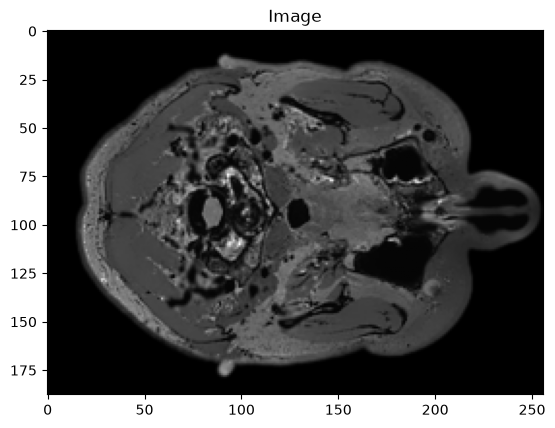

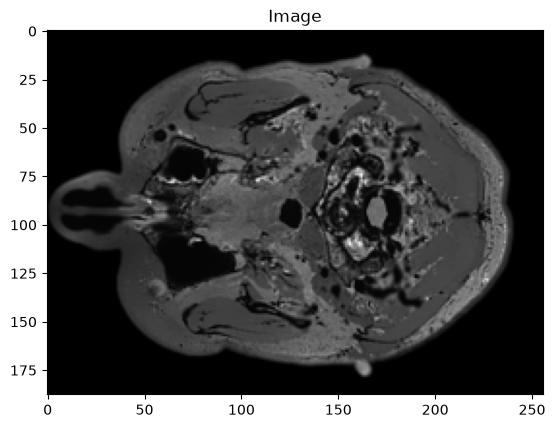

In [37]:
show_slice_3d(image, 0)
show_slice_3d(orientation_image)

### Scale the intensity

In [38]:
from monai.transforms import ScaleIntensity

In [54]:
image = nib.load('/Users/Isa/Documents/Curso Medical Image Processing/data/mri/chris_t2.nii.gz').get_fdata()
intensity_scaler = ScaleIntensity(minv=0, maxv=1)

scaled_array = intensity_scaler(image)

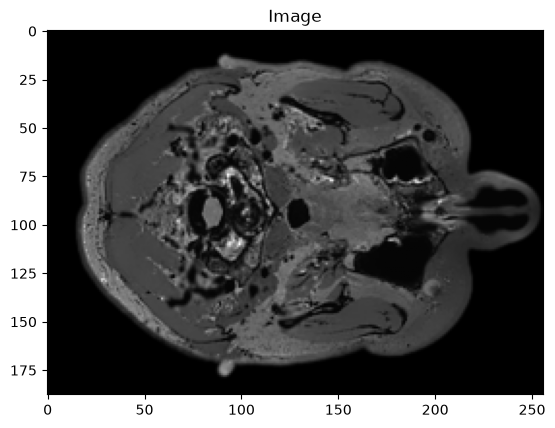

In [40]:
show_slice_3d(scaled_array)

In [41]:
print(np.min(image))
print(np.max(image))
print(np.min(scaled_array))
print(np.max(scaled_array))

0.0
255.0
0.0
1.0


In [42]:
from monai.transforms import ScaleIntensityRange

In [45]:
ranged_intensity_scaler = ScaleIntensityRange(a_min=-200, a_max=200, b_min=0, b_max=1, clip=True)
ranged_scaled_array = ranged_intensity_scaler(image)


In [46]:
print(np.min(image))
print(np.max(image))
print(np.min(ranged_scaled_array))
print(np.max(ranged_scaled_array))

0.0
255.0
0.5
1.0


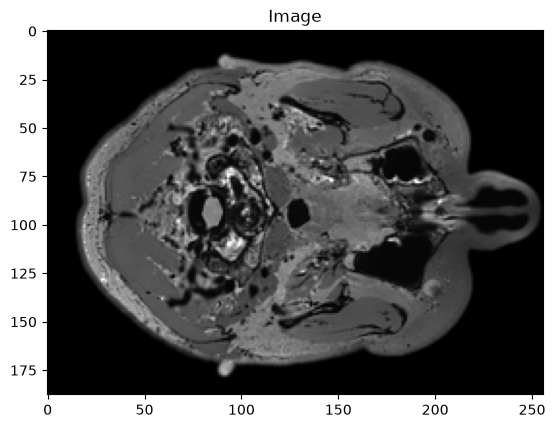

In [47]:
show_slice_3d(ranged_scaled_array)

### Random Gaussian Noise

In [48]:
from monai.transforms import GaussianSmooth

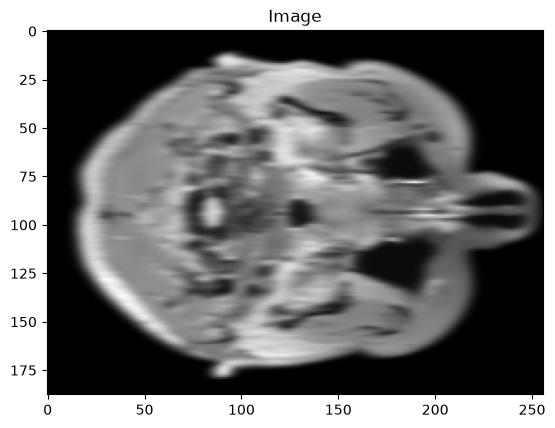

In [49]:
gaussian_smooth = GaussianSmooth(sigma=3)
smooth_image = gaussian_smooth(image)
show_slice_3d(smooth_image)

### Random rotation

In [50]:
from monai.transforms import RandRotate

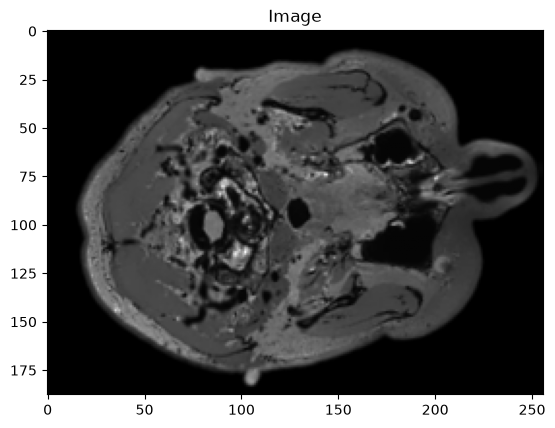

In [55]:
array = image[np.newaxis,:,:,:]

rotator = RandRotate(prob=0.9, range_z=0.6)
rotated_array = rotator(array)

show_slice_4d(rotated_array)

In [56]:
from monai.transforms import RandCoarseDropout

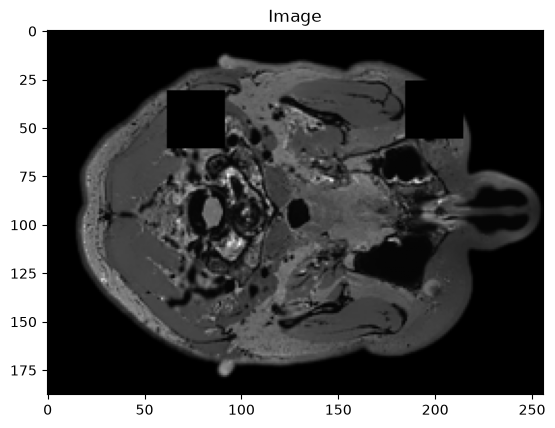

In [57]:
add_dropout = RandCoarseDropout(prob=1, holes=200, spatial_size=30,fill_value=0)

edited_volume = add_dropout(array)
show_slice_4d(edited_volume)